# 07 — Transformações geométricas e interpolação

**EP · Data Science Knowledge Base | Análise e Classificação de Imagens | Notebook 07/16**

**Pré-requisitos:** Python, NumPy e fundamentos de visualização; consulte os capítulos anteriores quando necessário.

**Escopo de validação:** As células principais usam dados sintéticos ou conjuntos fornecidos pelas bibliotecas. Dependências adicionais só são necessárias nos laboratórios explicitamente opcionais.

---

> **Biblioteca pessoal de Ciência de Dados** · Análise e Classificação de Imagens · Capítulo 07/16

> **Execução:** ainda não confirmada nesta versão; reinicie o kernel e execute as células obrigatórias localmente.


### Materiais complementares

- [Guia Técnico](./reference_materials/07_geometria_interpolacao.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_geometria_interpolacao.pdf)


## Como estudar este capítulo

1. Leia os fundamentos e consulte o Guia Técnico correspondente.
2. Reinicie o kernel e execute as células obrigatórias na sequência.
3. Confira tabelas, visualizações, saídas e limitações descritas no notebook.
4. Resolva o exercício antes de consultar a solução; execute laboratórios opcionais apenas em ambiente compatível.

**Pré-requisitos transversais:** Programação Python (01), visualização de dados (02), Estatística (03), Machine Learning (05) e Deep Learning (07), conforme o capítulo.


## Objetivos de aprendizagem

Aplicar translação, rotação e redimensionamento preservando coordenadas e escala.

Ao concluir, você deverá ser capaz de **explicar a técnica**, **executar o exemplo**, **interpretar limitações** e **justificar escolhas de avaliação**.

## Fundamentos conceituais

Transformações afins incluem rotação, cisalhamento e translação; projetivas (homografias) representam relações de perspectiva entre planos. Vizinho mais próximo preserva rótulos de máscaras; interpolação bilinear ou bicúbica costuma ser melhor para imagens contínuas. Resampling pode introduzir bordas e perda de detalhes.

### Conceito matemático

$$\begin{bmatrix}x’\\y’\\1\end{bmatrix}=H\begin{bmatrix}x\\y\\1\end{bmatrix}$$

A fórmula expressa o mecanismo principal do capítulo. Identifique unidades, dimensões e hipóteses antes de aplicar uma implementação.

## Experimento 1 — construção e medidas

Execute em kernel limpo. Exemplos usam datasets de bibliotecas instaláveis e não requerem download de arquivos externos.

In [1]:
from skimage.data import camera
from skimage.transform import rotate,resize
img=camera()
rot=rotate(img,15,resize=False,preserve_range=True)
small=resize(img,(128,128),preserve_range=True,anti_aliasing=True)
print('orig/rot:',img.shape,rot.shape,'redimensionada:',small.shape)

orig/rot: (512, 512) (512, 512) redimensionada: (128, 128)


## Experimento 2 — visualização, comparação ou validação

Observe não apenas o valor obtido, mas o que o experimento **realmente demonstra**.

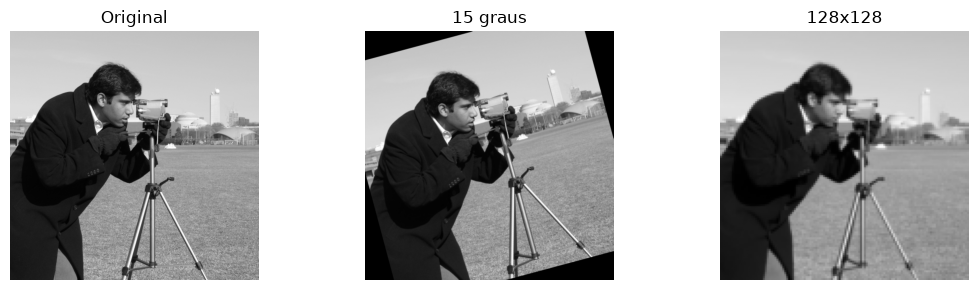

In [2]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,3,figsize=(11,3))
for a,v,t in zip(ax,[img,rot,small],['Original','15 graus','128x128']):a.imshow(v,cmap='gray');a.set_title(t);a.axis('off')
plt.tight_layout();plt.show()

## Interpretação técnica

Para comparar objetos, documente alterações geométricas e confira preservação de rótulos.

### Conexão com o acervo

Em vez de repetir capítulos de SVM, PCA, métricas e backpropagation, este notebook concentra a aplicação e limitações **em imagens**. Revisite as Disciplinas 05 e 07 para demonstrações matemáticas mais extensas.

## Exercício resolvido

**Problema:** Que interpolação deve ser usada para máscara com valores inteiros de classes?

**Resolução comentada:** Vizinho mais próximo, para não criar classes intermediárias inexistentes.

**Para praticar:** modifique um parâmetro do exemplo, registre a hipótese antes de executar e compare resultado, qualidade visual e custo computacional.

## Erros comuns e limitações

Nunca rotacione máscaras de classes com interpolação que misture os rótulos.

- Nunca ajustar parâmetros em cima do conjunto de teste final.
- Não confundir demonstração com validação científica completa.
- Documentar versões, fontes de dados e condições de execução.
- Não redistribuir fotografias de rostos ou datasets históricos sem licença e autorização.

## Consulta rápida

- **Pergunta-chave:** Aplicar translação, rotação e redimensionamento preservando coordenadas e escala.
- **Mecanismo:** Transformações afins incluem rotação, cisalhamento e translação; projetivas (homografias) representam relações de perspectiva entre planos.
- **Equação:** $\begin{bmatrix}x’\\y’\\1\end{bmatrix}=H\begin{bmatrix}x\\y\\1\end{bmatrix}$
- **Verificação:** interpretar formato dos dados, hipótese e saída antes de utilizar em um projeto.

### Referências de estudo

- Apresentações originais da disciplina (PDF consolidado).
- Documentação: [scikit-image](https://scikit-image.org/docs/stable/), [OpenCV](https://docs.opencv.org/4.x/), [scikit-learn](https://scikit-learn.org/stable/), conforme o capítulo.
- Para CNNs: [Keras](https://keras.io/).

## Aprofundamento v2 — auditoria e aplicação

**Ponto de atenção deste capítulo:** interpolação e contorno. Este complemento não substitui as seções e exemplos anteriores.

**Verificação conceitual.** Explique, com suas palavras, em qual etapa do fluxo de trabalho o tema **interpolação e contorno** pode produzir conclusões enganosas. Indique um indicador observável, um teste mínimo e uma limitação do procedimento.

**Exercício de extensão.** Reproduza o experimento central deste notebook alterando **um parâmetro por vez**. Compare com uma linha de base simples, reporte a variação da métrica pertinente e justifique o resultado. Quando houver treino/teste, qualquer etapa que aprenda parâmetros deve usar apenas o treino.

**Checklist de conclusão:** (1) entradas identificadas; (2) sementes registradas; (3) saídas interpretadas; (4) premissas explicitadas; (5) dados originais não sobrescritos.


### Exercício resolvido — protocolo mínimo de validação

**Enunciado.** Proponha uma comparação para **interpolação e contorno** sem contaminar a avaliação.

**Solução orientadora.** Defina uma hipótese falsificável, escolha um baseline simples, fixe uma divisão adequada ao problema, altere uma única decisão metodológica e compare métricas no conjunto reservado. Não transforme exemplos sintéticos em conclusões sobre populações reais. Documente a configuração e os casos de falha. Quando o tema não envolver predição, substitua o baseline por uma implementação de referência e compare correção, cobertura e custo.
